# Formative 2: Modeling Human Activity States Using Hidden Markov Models

**Author:** Ivan Manzi Ya Musana | individual assignment (one student, one iPhone 13)

**Goal.** Recognise four activity states (**standing, walking, jumping, still**) from smartphone accelerometer and
gyroscope signals with a Hidden Markov Model written from scratch in numpy: log-space forward-backward, Baum-Welch with a
log-likelihood convergence check, and Viterbi decoding.

**Pipeline.** raw zips in `Data/` &rarr; `scripts/make_clean_dataset.py` &rarr; `Data_clean/{train,test}` &rarr; 2 s windows &rarr;
44 time/frequency features &rarr; log and z-score (training statistics only) &rarr; Gaussian-emission HMM &rarr; Viterbi
decoding of unseen test recordings.

**Rules fixed before any test result is used**
* Test = the recordings I named by hand in separate sessions; train = all other recordings. The split never looks at the signal.
* Every model choice (variance floor, whether Baum-Welch updates pi) is made by leave-one-clip-out accuracy on the **training** clips only; ties go to the simpler option.
* Test clips are used only for reporting.

Every number in this notebook is computed by the cells below; `results/` holds copies. Sensor units are not stated in the files:
I label them m/s&sup2; and rad/s with an asterisk (inferred, **UNVERIFIED**).

## 1. Setup and data

In [1]:
import json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ROOT = Path.cwd()
if not (ROOT / "Data_clean").exists():          # allow running from a sub-folder
    ROOT = ROOT.parent
assert (ROOT / "Data_clean").exists(), "Data_clean/ not found - run: python scripts/make_clean_dataset.py"
DATA, FIG, RES = ROOT / "Data_clean", ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]      # HMM hidden states Z (state k <-> activity k)
K = len(ACTIVITIES)
LABEL = {a: i for i, a in enumerate(ACTIVITIES)}
COLORS = {"standing": "#4C78A8", "walking": "#F58518", "jumping": "#E45756", "still": "#54A24B"}
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
WIN_S, HOP_S = 2.0, 1.0                                       # window length and hop (seconds)
MIN_TOTAL_S = 90.0                                            # required usable seconds per activity
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.0


**Cleaning rules** (`scripts/make_clean_dataset.py`; identical for every recording, `Data/` is never modified)
1. Align accelerometer and gyroscope by nearest timestamp (5 ms), matching columns by name (the raw accelerometer export is ordered z, y, x).
2. Trim `TRIM_S` seconds from both ends. `TRIM_S` is the **largest of 1.0, 0.75 and 0.5 s for which every activity reaches 90 s** (sweep below).
3. Edge-transient rule: drop an outermost 1 s segment (at most 3 per end) while its accelerometer-magnitude std exceeds 2x the median 1 s std of the clip. It uses no labels and no model output. It was added after an earlier run showed that the test errors sat at the start of clips; it is applied to every recording.
4. Keep clips of 5-10 s (central crop above 10 s).
5. Exclude the one recording whose signal contradicts its label.

In [2]:
manifest = pd.read_csv(DATA / "manifest.csv")
excluded = pd.read_csv(DATA / "excluded.csv")
sweep = pd.read_csv(DATA / "trim_sweep.csv")
clips = []
for r in manifest.itertuples():
    df = pd.read_csv(DATA / r.split / r.new_name)
    assert list(df.columns) == ["timestamp"] + SENSOR_COLS and not df.isna().any().any()
    clips.append(dict(name=r.new_name, split=r.split, activity=r.activity, df=df, notes=str(r.notes)))

summary = manifest.pivot_table(index="activity", columns="split", values="duration_s",
                               aggfunc=["count", "sum"]).reindex(ACTIVITIES)
summary.columns = [f"{'files' if a == 'count' else 'seconds'} ({s})" for a, s in summary.columns]
summary["seconds (total)"] = summary["seconds (train)"] + summary["seconds (test)"]
summary["reaches 90 s"] = summary["seconds (total)"] >= MIN_TOTAL_S
display(summary.round(1))
print("clips:", len(clips), "| train:", sum(c["split"] == "train" for c in clips),
      "| test:", sum(c["split"] == "test" for c in clips), "| trim used:", manifest.trim_s.iloc[0], "s")
print("\nTrim sweep (usable seconds per activity after all rules):"); display(sweep)
print("Excluded recordings and removed edge segments (originals untouched in Data/):")
display(excluded.assign(reason=excluded.reason.str.slice(0, 95)))

,files (test),files (train),seconds (test),seconds (train),seconds (total),reaches 90 s
activity,,,,,,
standing,2,10,19.3,73.0,92.3,True
walking,3,10,27.1,81.6,108.6,True
jumping,3,10,20.8,87.0,107.8,True
still,2,10,16.1,72.1,88.2,False


clips: 50 | train: 40 | test: 10 | trim used: 0.5 s

Trim sweep (usable seconds per activity after all rules):


,trim_s,standing,walking,jumping,still,clips,all_activities_reach_90s,selected
0,1.00,76.9,97.7,95.5,81.2,49,False,False
1,0.75,86.1,103.2,101.9,90.1,51,False,False
2,0.50,92.3,108.6,107.8,88.2,50,False,True


Excluded recordings and removed edge segments (originals untouched in Data/):


,original_zip,activity,kind,new_name,reason
0,Data/standing/standing_02-2026-10-28_17-23-27.zip,standing,recording,NaN,"mislabeled: signal looks like walking, not sta..."
1,Data/still/still01-2026-10-28_17-23-58.zip,still,recording,NaN,shorter than 5 s after trimming 0.5 s per end ...
2,Data/standing/2026-10-28_17-16-53.zip,standing,segment,standing_02.csv,removed 2 s at the start: 1-s accel-magnitude ...
3,Data/standing/2026-10-28_17-17-39.zip,standing,segment,standing_07.csv,removed 1 s at the start: 1-s accel-magnitude ...
4,Data/standing/2026-10-28_17-18-17.zip,standing,segment,standing_11.csv,removed 1 s at the start: 1-s accel-magnitude ...
5,Data/still/2026-10-28_17-13-26.zip,still,segment,still_02.csv,removed 1 s at the start: 1-s accel-magnitude ...
6,Data/still/2026-10-28_17-13-39.zip,still,segment,still_03.csv,removed 1 s at the end: 1-s accel-magnitude st...
7,Data/still/still-2026-10-28_16-40-36.zip,still,segment,still_01.csv,removed 2 s at the start: 1-s accel-magnitude ...
8,Data/still/still-2026-10-28_16-40-36.zip,still,segment,still_01.csv,removed 2 s at the end: 1-s accel-magnitude st...


## 2. Sample signals

Five seconds of accelerometer (left) and gyroscope (right) from the typical training clip of each activity (accelerometer-magnitude
std closest to the activity median, clips with a QC flag excluded). Amplitudes differ by orders of magnitude, so every panel has its own y-scale.
&#42;Units are inferred (m/s&sup2;, rad/s), not stated in the files: **UNVERIFIED**.

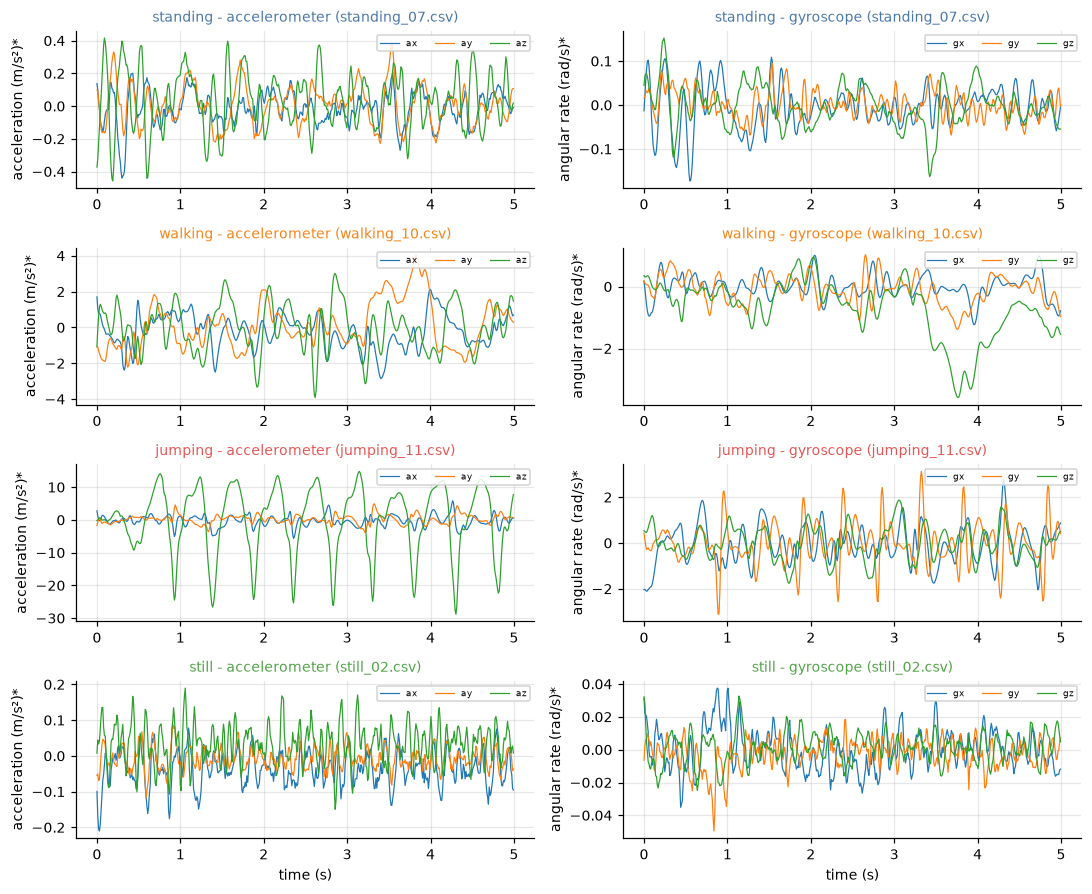

In [3]:
def accel_std(c):
    return np.sqrt((c["df"][["ax", "ay", "az"]] ** 2).sum(axis=1)).std()

def example_clip(act):
    '''Unflagged training clip whose accelerometer-magnitude std is closest to the activity median.'''
    cands = [c for c in clips if c["activity"] == act and c["split"] == "train" and "QC:" not in c["notes"]]
    med = np.median([accel_std(c) for c in cands])
    return min(cands, key=lambda c: abs(np.log(accel_std(c)) - np.log(med)))

fig, axes = plt.subplots(4, 2, figsize=(10, 8.2))
for i, act in enumerate(ACTIVITIES):
    c = example_clip(act); seg = c["df"][c["df"].timestamp <= 5.0]
    for j, (cols, ylab) in enumerate([(["ax", "ay", "az"], "acceleration (m/s²)*"), (["gx", "gy", "gz"], "angular rate (rad/s)*")]):
        for col in cols:
            axes[i, j].plot(seg.timestamp, seg[col], lw=.8, label=col)
        axes[i, j].set_title(f"{act} - {'accelerometer' if j == 0 else 'gyroscope'} ({c['name']})", fontsize=9, color=COLORS[act])
        axes[i, j].set_ylabel(ylab); axes[i, j].legend(loc="upper right", ncol=3, fontsize=6, frameon=True, framealpha=.85, borderpad=.3)
        if i == 3: axes[i, j].set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(FIG / "fig01_sample_signals.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Sampling-rate handling

All 52 recordings come from **one device (iPhone 13)** logged at the same nominal rate (`sampleRateMs = 10`, i.e. 100 Hz), so there is no
cross-device rate mismatch to harmonise. I still **measure** the rate of every cleaned clip from its timestamps instead of assuming it.
Accelerometer and gyroscope were aligned by nearest timestamp (`merge_asof`, 5 ms tolerance) in `scripts/make_clean_dataset.py`; this also
resolved the one recording with 916 accelerometer but 917 gyroscope rows. If the measured rate is uniform, resampling is unnecessary and would
only add interpolation error.

nominal rate (metadata): 100 Hz | measured per clip: min 100.105, max 100.124, mean 100.118, std 0.0050 Hz
sample spacing over all 39,745 steps: min 9.98 ms, max 9.99 ms, mean 9.988 ms
-> rate is uniform (spread < 0.1 Hz, no gap > 11 ms): no resampling required. FS used for window length and FFT bins = 100.118 Hz


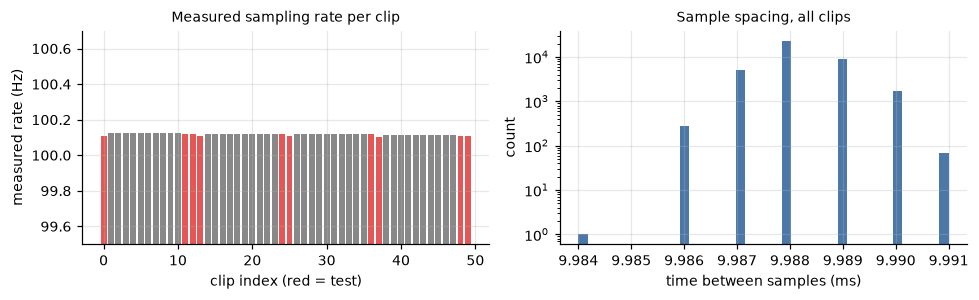

In [4]:
rows, all_dt = [], []
for c in clips:
    t = c["df"].timestamp.to_numpy(); dt = np.diff(t)
    all_dt.append(dt * 1e3)
    rows.append(dict(name=c["name"], split=c["split"], hz=(len(t) - 1) / (t[-1] - t[0]),
                     dt_min_ms=dt.min() * 1e3, dt_max_ms=dt.max() * 1e3))
hz_tab = pd.DataFrame(rows); all_dt = np.concatenate(all_dt)
FS = float(hz_tab.hz.mean())
print(f"nominal rate (metadata): 100 Hz | measured per clip: min {hz_tab.hz.min():.3f}, max {hz_tab.hz.max():.3f}, "
      f"mean {FS:.3f}, std {hz_tab.hz.std():.4f} Hz")
print(f"sample spacing over all {len(all_dt):,} steps: min {all_dt.min():.2f} ms, max {all_dt.max():.2f} ms, "
      f"mean {all_dt.mean():.3f} ms")
assert hz_tab.hz.max() - hz_tab.hz.min() < 0.1 and all_dt.max() < 11.0     # uniform -> no resampling needed
print("-> rate is uniform (spread < 0.1 Hz, no gap > 11 ms): no resampling required. FS used for window length and FFT bins =", round(FS, 3), "Hz")

fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].bar(range(len(hz_tab)), hz_tab.hz, color=["#888" if s == "train" else "#E45756" for s in hz_tab.split])
ax[0].set_ylim(99.5, 100.7); ax[0].set_xlabel("clip index (red = test)"); ax[0].set_ylabel("measured rate (Hz)")
ax[0].set_title("Measured sampling rate per clip", fontsize=9)
ax[1].hist(all_dt, bins=40, color="#4C78A8"); ax[1].set_yscale("log")
ax[1].set_xlabel("time between samples (ms)"); ax[1].set_ylabel("count"); ax[1].set_title("Sample spacing, all clips", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig02_sampling_rate.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Windowing

* **Window = 2 s, hop = 1 s (50 % overlap)**, converted to samples with the measured rate: `WIN = round(2 s x FS)`, `HOP = round(1 s x FS)`.
* Why 2 s: at my measured walking cadence (median dominant frequency about 1.5 Hz on two axes, see 8.6) a window holds about three steps, so the walking rhythm is visible; a 2 s
  FFT has 0.5 Hz resolution, enough to separate walking (about 1.5 Hz) from jumping (about 2 Hz); and it is short enough that a window rarely spans two activities.
* 50 % overlap doubles the number of observations. Overlapping windows are correlated, so train and test are split **by clip**, never by window.
* Each window inherits the label of its (single-activity) clip.

In [5]:
WIN, HOP = int(round(WIN_S * FS)), int(round(HOP_S * FS))
print(f"window = {WIN_S:g} s x {FS:.3f} Hz = {WIN} samples | hop = {HOP_S:g} s = {HOP} samples ({1 - HOP / WIN:.0%} overlap)")

def make_windows(X, win=WIN, hop=HOP):
    n = (len(X) - win) // hop + 1
    return np.stack([X[i * hop:i * hop + win] for i in range(n)])

for c in clips:
    c["W"] = make_windows(c["df"][SENSOR_COLS].to_numpy())
    c["y"] = np.full(len(c["W"]), LABEL[c["activity"]])
wtab = pd.DataFrame([dict(activity=c["activity"], split=c["split"], windows=len(c["W"])) for c in clips])
display(wtab.pivot_table(index="activity", columns="split", values="windows", aggfunc="sum").reindex(ACTIVITIES))
print("window tensor example:", clips[0]["W"].shape, "(windows, samples, channels)")

window = 2 s x 100.118 Hz = 200 samples | hop = 1 s = 100 samples (50% overlap)


split,test,train
activity,,
standing,17,58
walking,24,68
jumping,17,73
still,13,58


window tensor example: (5, 200, 6) (windows, samples, channels)


## 5. Feature extraction (44 features per window)

For **each sensor** (accelerometer, gyroscope) and window:

| Family | Features (per sensor) | Why it separates the activities |
|---|---|---|
| Time domain | **mean** x,y,z (3) | residual bias / posture drift; near 0 for the gravity-free accelerometer |
| | **std** x,y,z (3) | movement intensity: still &lt; standing &lt; walking &lt; jumping |
| | **RMS** x,y,z (3) | overall signal energy including any offset |
| | **SMA** (1) = mean(\|x\|+\|y\|+\|z\|) | classic whole-body activity-intensity measure |
| | **axis correlation** xy, xz, yz (3) | direction of motion: jumping is dominated by one axis, walking couples several axes |
| Frequency (FFT of the mean-removed, Hann-tapered window) | **dominant frequency** per axis (3), searched in 0.5-10 Hz | cadence: about 1.5 Hz walking, about 2 Hz jumping, noise-like for still/standing |
| | **spectral energy** per axis (3) | how much power sits in the motion band |
| | **spectral entropy** per axis (3) | periodic movement = low entropy; sensor noise / sway = high entropy |

The dominant frequency is computed **per axis**, not on the magnitude: rectifying the magnitude folds the spectrum (a 2 Hz jump shows up at 4 Hz)
and gave unstable values for walking.

In [6]:
SENSORS = {"acc": slice(0, 3), "gyro": slice(3, 6)}
PAIRS = [(0, 1, "xy"), (0, 2, "xz"), (1, 2, "yz")]

def extract_features(W):
    '''W: (n_windows, WIN, 6) -> (features (n_windows, 44), names). Uses the measured rate FS for the FFT bins.'''
    n, L, _ = W.shape
    f = np.fft.rfftfreq(L, d=1.0 / FS)
    band = (f >= 0.5) & (f <= 10.0)
    taper = np.hanning(L)
    cols, names = [], []
    def add(arr, base, axes="xyz"):
        arr = arr.reshape(n, -1)
        for i, a in enumerate(axes if arr.shape[1] > 1 else [""]):
            cols.append(arr[:, i]); names.append(f"{base}_{a}" if a else base)
    for s, sl in SENSORS.items():
        S = W[:, :, sl]
        mean, std = S.mean(1), S.std(1)
        Sc = S - mean[:, None, :]
        add(mean, f"{s}_mean")
        add(std, f"{s}_std")
        add(np.sqrt((S ** 2).mean(1)), f"{s}_rms")
        add(np.abs(S).sum(2).mean(1), f"{s}_sma")
        for i, j, lab in PAIRS:
            add((Sc[:, :, i] * Sc[:, :, j]).mean(1) / (std[:, i] * std[:, j] + 1e-12), f"{s}_corr_{lab}")
        P = np.abs(np.fft.rfft(Sc * taper[None, :, None], axis=1)) ** 2          # (n, bins, 3)
        add(f[band][np.argmax(P[:, band, :], axis=1)], f"{s}_domfreq")
        add(P[:, 1:, :].sum(1) / L, f"{s}_energy")
        p = P[:, 1:, :] / (P[:, 1:, :].sum(1, keepdims=True) + 1e-12)
        add(-(p * np.log(p + 1e-12)).sum(1) / np.log(p.shape[1]), f"{s}_entropy")
    return np.stack(cols, axis=1), names

for c in clips:
    c["F_raw"], FEATURE_NAMES = extract_features(c["W"])
D = len(FEATURE_NAMES)
print(D, "features per window:"); print(FEATURE_NAMES)
assert all(np.isfinite(c["F_raw"]).all() for c in clips)

44 features per window:
['acc_mean_x', 'acc_mean_y', 'acc_mean_z', 'acc_std_x', 'acc_std_y', 'acc_std_z', 'acc_rms_x', 'acc_rms_y', 'acc_rms_z', 'acc_sma', 'acc_corr_xy', 'acc_corr_xz', 'acc_corr_yz', 'acc_domfreq_x', 'acc_domfreq_y', 'acc_domfreq_z', 'acc_energy_x', 'acc_energy_y', 'acc_energy_z', 'acc_entropy_x', 'acc_entropy_y', 'acc_entropy_z', 'gyro_mean_x', 'gyro_mean_y', 'gyro_mean_z', 'gyro_std_x', 'gyro_std_y', 'gyro_std_z', 'gyro_rms_x', 'gyro_rms_y', 'gyro_rms_z', 'gyro_sma', 'gyro_corr_xy', 'gyro_corr_xz', 'gyro_corr_yz', 'gyro_domfreq_x', 'gyro_domfreq_y', 'gyro_domfreq_z', 'gyro_energy_x', 'gyro_energy_y', 'gyro_energy_z', 'gyro_entropy_x', 'gyro_entropy_y', 'gyro_entropy_z']


## 6. Normalisation

1. **log10 of the strictly positive, heavy-tailed amplitude features** (std, RMS, SMA, spectral energy). They differ by orders of magnitude
   between still and jumping, so on a linear scale jumping would dominate and still/standing would collapse to the same value; a Gaussian also fits a
   log-scaled positive quantity better.
2. **Z-score with the mean and standard deviation of the TRAINING windows only**, applied unchanged to the test windows (no test information enters the
   model). Features have different units and ranges (Hz, m/s&sup2;, rad/s, unit-free correlations) and the Gaussian emissions share one variance floor,
   so comparable scales are needed for the floor and for numerical conditioning.

Caveat: a Gaussian with its own variance per state is invariant to an affine rescaling, so z-scoring acts only through the variance floor and numerical
conditioning; the log transform is the step that actually reshapes the distributions.

In [7]:
LOG_MASK = np.array([n.split("_")[1] in ("std", "rms", "sma", "energy") for n in FEATURE_NAMES])
print("log10-transformed features:", int(LOG_MASK.sum()), "of", D)

def log_scale(F):
    G = F.copy(); G[:, LOG_MASK] = np.log10(G[:, LOG_MASK] + 1e-12); return G

def fit_normalizer(F):
    mu, sd = F.mean(0), F.std(0)
    return mu, np.where(sd < 1e-9, 1.0, sd)

for c in clips:
    c["F"] = log_scale(c["F_raw"])
train_clips = [c for c in clips if c["split"] == "train"]
test_clips = [c for c in clips if c["split"] == "test"]
NORM = fit_normalizer(np.concatenate([c["F"] for c in train_clips]))       # training windows only
for c in clips:
    c["Z"] = (c["F"] - NORM[0]) / NORM[1]
Ztr = np.concatenate([c["Z"] for c in train_clips]); Zte = np.concatenate([c["Z"] for c in test_clips])
print(f"train z-scores: mean {Ztr.mean():+.3f}, std {Ztr.std():.3f} | test z-scores (not refit): "
      f"mean {Zte.mean():+.3f}, std {Zte.std():.3f}")

log10-transformed features: 20 of 44
train z-scores: mean -0.000, std 1.000 | test z-scores (not refit): mean -0.005, std 1.010


## 7. Hidden Markov Model from scratch (numpy)

### 7.1 Model and algorithms
* **Z** (hidden states): standing, walking, jumping, still. **X** (observations): the z-scored 44-dimensional window features.
* **B** (emissions): one diagonal Gaussian per state with a variance floor, so a state cannot collapse onto a few windows. **A**: 4x4 transition matrix. **pi**: initial distribution.
* Parameters start from the labelled training windows (class means and variances, empirical transitions, pi) and are refined with **Baum-Welch** in log-space.
  It stops when the change in total log-likelihood is below epsilon; the iteration cap is only a safeguard. **Viterbi** (log-space) decodes the most likely state path.
* Why these two: Baum-Welch trains the model; Viterbi turns a window sequence into activity labels, which is what sensitivity, specificity and the confusion matrix score.
* **Training sequences.** No transition between activities occurs inside one of my clips, so whole training clips are concatenated in seeded random order (10 shuffles).
  The diagonal of A therefore reflects clip length and the off-diagonal entries reflect the shuffling, not real behaviour.
* **pi.** Estimating pi from the first clip of only 10 shuffles is noisy, so pi starts at the share of training clips per activity. Section 7.4 decides, on training data only, whether Baum-Welch may update it.

In [8]:
def lse(a, axis):
    '''Numerically stable log-sum-exp along an axis.'''
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    return np.squeeze(m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)), axis=axis)

def log_emission(X, mu, var):
    '''Diagonal-Gaussian log density. X (T,D), mu/var (K,D) -> (T,K).'''
    d = X[:, None, :] - mu[None]
    return -0.5 * (np.log(2 * np.pi * var)[None] + d ** 2 / var[None]).sum(-1)

def forward(logB, logA, logpi):
    '''Log forward variables alpha (T,K) and the sequence log-likelihood.'''
    T, Kk = logB.shape
    la = np.empty((T, Kk)); la[0] = logpi + logB[0]
    for t in range(1, T):
        la[t] = logB[t] + lse(la[t - 1][:, None] + logA, axis=0)
    return la, lse(la[-1], axis=0)

def backward(logB, logA):
    '''Log backward variables beta (T,K).'''
    T, Kk = logB.shape
    lb = np.zeros((T, Kk))
    for t in range(T - 2, -1, -1):
        lb[t] = lse(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
    return lb

def viterbi(logB, logA, logpi):
    '''Most likely state path (log-space). Returns (path, log-probability).'''
    T, Kk = logB.shape
    delta = np.empty((T, Kk)); psi = np.zeros((T, Kk), dtype=int)
    delta[0] = logpi + logB[0]
    for t in range(1, T):
        cand = delta[t - 1][:, None] + logA
        psi[t] = cand.argmax(0); delta[t] = cand.max(0) + logB[t]
    path = np.empty(T, dtype=int); path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1, path[t + 1]]
    return path, float(delta[-1].max())

def init_from_labels(seqs_X, seqs_y, var_floor, a_pseudo=1e-2, given_pi=None):
    '''Supervised initial parameters from labelled sequences (state k = activity k). given_pi overrides the estimated pi.'''
    X, y = np.concatenate(seqs_X), np.concatenate(seqs_y)
    mu = np.stack([X[y == k].mean(0) for k in range(K)])
    var = np.maximum(np.stack([X[y == k].var(0) for k in range(K)]), var_floor)
    A = np.full((K, K), a_pseudo); pi = np.full(K, a_pseudo)
    for yy in seqs_y:
        np.add.at(A, (yy[:-1], yy[1:]), 1.0); pi[yy[0]] += 1.0
    pi = pi / pi.sum() if given_pi is None else np.asarray(given_pi, dtype=float)
    return dict(mu=mu, var=var, A=A / A.sum(1, keepdims=True), pi=pi)

def baum_welch(seqs_X, params, var_floor, eps=1e-4, max_iter=500, a_pseudo=1e-2, update_pi=False):
    '''Baum-Welch (EM) over several sequences. Stops when |LL_t - LL_(t-1)| < eps (total log-likelihood).
    update_pi=False keeps pi fixed. Returns (params, LL history, converged flag); history[0] is the LL of the initial parameters.'''
    mu, var, A, pi = (params[k].copy() for k in ("mu", "var", "A", "pi"))
    Kk = mu.shape[0]
    hist, converged = [], False
    for it in range(max_iter + 1):
        logA, logpi = np.log(A), np.log(pi)
        g0 = np.zeros(Kk); xi_sum = np.zeros((Kk, Kk)); gs = np.zeros(Kk)
        gx = np.zeros_like(mu); gxx = np.zeros_like(mu); total = 0.0
        for X in seqs_X:
            logB = log_emission(X, mu, var)
            la, ll = forward(logB, logA, logpi); lb = backward(logB, logA)
            g = np.exp(la + lb - ll)
            xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll).sum(0)
            total += ll; g0 += g[0]; xi_sum += xi; gs += g.sum(0); gx += g.T @ X; gxx += g.T @ (X ** 2)
        hist.append(total)
        if it > 0 and abs(hist[-1] - hist[-2]) < eps:
            converged = True; break
        if it == max_iter:
            break
        mu = gx / gs[:, None]
        var = np.maximum(gxx / gs[:, None] - mu ** 2, var_floor)
        A = xi_sum + a_pseudo; A /= A.sum(1, keepdims=True)
        if update_pi:
            pi = g0 + a_pseudo; pi /= pi.sum()
    return dict(mu=mu, var=var, A=A, pi=pi), np.array(hist), converged

def decode(params, X):
    logB = log_emission(X, params["mu"], params["var"])
    path, _ = viterbi(logB, np.log(params["A"]), np.log(params["pi"]))
    return path, logB

def check_params(p, var_floor=None, tol=1e-9):
    '''Assert a valid parameter set: rows of A and pi sum to 1, everything finite and positive.'''
    assert np.allclose(p["A"].sum(1), 1.0, atol=tol), "rows of A must sum to 1"
    assert abs(p["pi"].sum() - 1.0) < tol, "pi must sum to 1"
    assert all(np.isfinite(p[k]).all() for k in ("mu", "var", "A", "pi")), "non-finite parameter"
    assert (p["A"] > 0).all() and (p["pi"] > 0).all() and (p["var"] > 0).all(), "A, pi and variances must be positive"
    if var_floor is not None:
        assert (p["var"] >= var_floor - 1e-12).all(), "variance below the floor"

### 7.2 Correctness checks
1. On a tiny random HMM, the log-space forward algorithm must equal brute-force enumeration over all state paths, Viterbi must find the brute-force best path, and Baum-Welch must never decrease the likelihood.
2. On the textbook Healthy/Fever HMM, whose answer is known by hand, Viterbi must return the path Healthy, Healthy, Fever with probability 0.6 x 0.5 x 0.7 x 0.4 x 0.3 x 0.6 = 0.01512.

In [9]:
# 1) brute force on a tiny random HMM
rng_t = np.random.default_rng(0)
Kt, Tt, Dt = 3, 6, 2
mu_t, var_t = rng_t.normal(size=(Kt, Dt)), rng_t.uniform(.5, 1.5, size=(Kt, Dt))
A_t = rng_t.dirichlet(np.ones(Kt), size=Kt); pi_t = rng_t.dirichlet(np.ones(Kt)); X_t = rng_t.normal(size=(Tt, Dt))
logB_t = log_emission(X_t, mu_t, var_t)
best, tot = (-np.inf, None), []
for path in itertools.product(range(Kt), repeat=Tt):
    lp = np.log(pi_t[path[0]]) + logB_t[0, path[0]] + sum(np.log(A_t[path[t - 1], path[t]]) + logB_t[t, path[t]] for t in range(1, Tt))
    tot.append(lp); best = max(best, (lp, path))
_, ll_fwd = forward(logB_t, np.log(A_t), np.log(pi_t))
vpath, vlp = viterbi(logB_t, np.log(A_t), np.log(pi_t))
assert abs(ll_fwd - lse(np.array(tot), axis=0)) < 1e-9, "forward != brute force"
assert tuple(vpath) == best[1] and abs(vlp - best[0]) < 1e-9, "viterbi != brute force"
lb_t = backward(logB_t, np.log(A_t))
assert abs(lse(np.log(pi_t) + logB_t[0] + lb_t[0], axis=0) - ll_fwd) < 1e-9, "forward and backward disagree"
_, h_t, _ = baum_welch([X_t, rng_t.normal(size=(8, Dt))], dict(mu=mu_t, var=var_t, A=A_t, pi=pi_t), 1e-3, eps=1e-8, max_iter=30, update_pi=True)
assert (np.diff(h_t) > -1e-9).all(), "Baum-Welch log-likelihood decreased"
print(f"random HMM: forward LL {ll_fwd:.6f} == brute force | Viterbi path == brute force | Baum-Welch LL non-decreasing over {len(h_t)} iterations: OK")

# 2) textbook example with a hand-computed answer (states: 0 = Healthy, 1 = Fever; observations: 0 = normal, 1 = cold, 2 = dizzy)
pi_h = np.array([0.6, 0.4])
A_h = np.array([[0.7, 0.3], [0.4, 0.6]])
B_h = np.array([[0.5, 0.4, 0.1], [0.1, 0.3, 0.6]])
obs_h = [0, 1, 2]                                                    # normal, cold, dizzy
path_h, logp_h = viterbi(np.log(B_h[:, obs_h].T), np.log(A_h), np.log(pi_h))
assert path_h.tolist() == [0, 0, 1], "expected Healthy, Healthy, Fever"
assert abs(np.exp(logp_h) - 0.01512) < 1e-12, "expected probability 0.01512"
print(f"textbook Healthy/Fever: Viterbi path = {['Healthy', 'Fever'][path_h[0]]}, {['Healthy', 'Fever'][path_h[1]]}, "
      f"{['Healthy', 'Fever'][path_h[2]]} with p = {np.exp(logp_h):.5f} (expected 0.01512): OK")

random HMM: forward LL -14.598944 == brute force | Viterbi path == brute force | Baum-Welch LL non-decreasing over 21 iterations: OK
textbook Healthy/Fever: Viterbi path = Healthy, Healthy, Fever with p = 0.01512 (expected 0.01512): OK


### 7.3 Variance floor (training data only)

Features such as the dominant frequency move in 0.5 Hz steps and can have almost no variance inside a class, hence the floor (in z-score units).
Rule, fixed in advance: leave-one-clip-out cross-validation on the training clips (normaliser re-fit in every fold, supervised initialisation, Viterbi on
the held-out clip); choose the **largest** floor among those with the best accuracy. Test clips are not used.

In [10]:
EPS, MAX_ITER, N_SEQ = 1e-4, 500, 10            # Baum-Welch stops when |dLL| < EPS (MAX_ITER is only a safeguard)

def build_sequences(files, n_seq, seed):
    '''Concatenate whole clips in seeded random order -> (list of X, list of y) sequences.'''
    rng = np.random.default_rng(seed); sx, sy = [], []
    for _ in range(n_seq):
        order = rng.permutation(len(files))
        sx.append(np.concatenate([files[i]["Z"] for i in order])); sy.append(np.concatenate([files[i]["y"] for i in order]))
    return sx, sy

def expected_pi(files):
    '''Start distribution of a randomly ordered concatenation = share of clips per activity.'''
    cnt = np.array([sum(f["y"][0] == k for f in files) for k in range(K)], dtype=float)
    return cnt / cnt.sum()

def zscored(files, norm):
    return [dict(f, Z=(f["F"] - norm[0]) / norm[1]) for f in files]

def lofo_accuracy(var_floor, bw_update_pi=None, n_seq=3):
    '''Leave-one-clip-out window accuracy on the TRAINING clips. bw_update_pi=None: supervised initialisation only;
    True/False: refine with Baum-Welch (pi updated / fixed). State k is read as activity k (checked in 7.5).'''
    correct = total = 0
    for i, held in enumerate(train_clips):
        rest = [c for j, c in enumerate(train_clips) if j != i]
        norm = fit_normalizer(np.concatenate([c["F"] for c in rest]))
        rest_z, held_z = zscored(rest, norm), zscored([held], norm)[0]
        sx, sy = build_sequences(rest_z, n_seq, SEED)
        p = init_from_labels(sx, sy, var_floor, given_pi=expected_pi(rest))
        if bw_update_pi is not None:
            p, _, _ = baum_welch(sx, p, var_floor, eps=EPS, max_iter=MAX_ITER, update_pi=bw_update_pi)
        path, _ = decode(p, held_z["Z"])
        correct += int((path == held_z["y"]).sum()); total += len(path)
    return correct / total

FLOORS = [0.01, 0.05, 0.1, 0.25, 0.5]
cv = pd.DataFrame({"var_floor": FLOORS, "LOFO window accuracy (train only)": [lofo_accuracy(v) for v in FLOORS]})
display(cv.round(4))
best_acc = cv.iloc[:, 1].max()
VAR_FLOOR = float(cv.loc[cv.iloc[:, 1] >= best_acc - 1e-12, "var_floor"].max())
print("selected variance floor:", VAR_FLOOR)

,var_floor,LOFO window accuracy (train only)
0,0.01,0.9728
1,0.05,0.9728
2,0.10,0.9728
3,0.25,0.9805
4,0.50,0.9844


selected variance floor: 0.5


### 7.4 Should Baum-Welch update pi? (training data only)

Rule, fixed in advance: compare leave-one-clip-out accuracy on the training clips for (a) pi fixed at the training-clip shares and (b) pi re-estimated by
Baum-Welch (both refined with Baum-Welch at the floor chosen above). Use (b) only if it is strictly more accurate; ties keep (a). Training log-likelihood is not
used: extra free parameters can never lower it, so it cannot arbitrate.

In [11]:
pi_cv = pd.DataFrame({"Baum-Welch updates pi": [False, True],
                      "LOFO window accuracy (train only)": [lofo_accuracy(VAR_FLOOR, False), lofo_accuracy(VAR_FLOOR, True)]})
display(pi_cv.round(4))
UPDATE_PI = bool(pi_cv.iloc[1, 1] > pi_cv.iloc[0, 1] + 1e-12)
LOFO_FINAL = float(pi_cv.iloc[int(UPDATE_PI), 1])
print("decision: Baum-Welch", "UPDATES pi" if UPDATE_PI else "keeps pi FIXED",
      "(updating is not strictly more accurate on the training clips)" if not UPDATE_PI else "(strictly more accurate on the training clips)")

,Baum-Welch updates pi,LOFO window accuracy (train only)
0,False,0.9844
1,True,0.9844


decision: Baum-Welch keeps pi FIXED (updating is not strictly more accurate on the training clips)


### 7.5 Initialise, then train with Baum-Welch (convergence-checked)

10 training sequences, each a random concatenation of the 40 training clips (257 windows)
pi at initialisation (share of training clips per activity): {'standing': 0.25, 'walking': 0.25, 'jumping': 0.25, 'still': 0.25}


Baum-Welch: CONVERGED after 4 iterations (|dLL| = 3.24e-05 < eps = 0.0001); total train LL -95853.16 -> -95820.97
log-likelihood is non-decreasing; smallest step: 3.242e-05 | rows of A sum to 1, pi sums to 1, all parameters finite: OK
floor diagnostic (training data only): median un-floored within-class variance = 0.062 z-units^2, floor = 0.5; 79.5% of the 4 x 44 state variances sit exactly at the floor after Baum-Welch


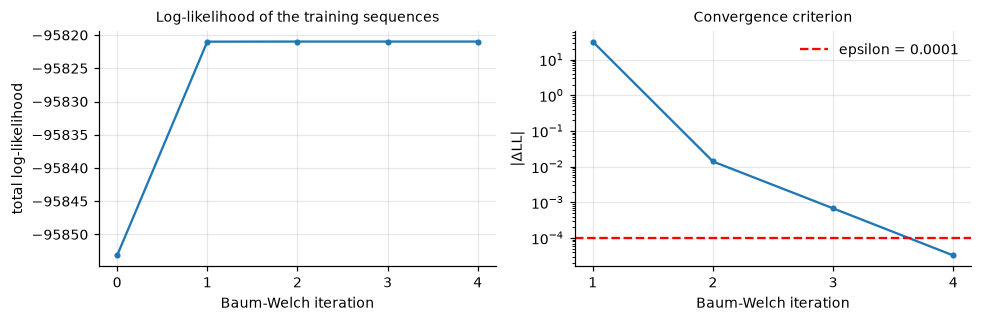

In [12]:
seq_X, seq_y = build_sequences(train_clips, N_SEQ, SEED)
print(f"{N_SEQ} training sequences, each a random concatenation of the {len(train_clips)} training clips ({len(seq_X[0])} windows)")
PI0 = expected_pi(train_clips)
print("pi at initialisation (share of training clips per activity):", {a: round(float(p), 3) for a, p in zip(ACTIVITIES, PI0)})
params_init = init_from_labels(seq_X, seq_y, VAR_FLOOR, given_pi=PI0)
params_bw, ll_hist, converged = baum_welch(seq_X, params_init, VAR_FLOOR, eps=EPS, max_iter=MAX_ITER, update_pi=UPDATE_PI)
n_iter = len(ll_hist) - 1
check_params(params_init, VAR_FLOOR); check_params(params_bw, VAR_FLOOR)
assert converged, "Baum-Welch hit max_iter without meeting the |dLL| < eps criterion"
assert (np.diff(ll_hist) > -1e-6).all(), "Baum-Welch log-likelihood decreased"
print(f"Baum-Welch: CONVERGED after {n_iter} iterations (|dLL| = {abs(ll_hist[-1] - ll_hist[-2]):.2e} < eps = {EPS:g}); "
      f"total train LL {ll_hist[0]:.2f} -> {ll_hist[-1]:.2f}")
print("log-likelihood is non-decreasing; smallest step:", f"{np.diff(ll_hist).min():.3e}",
      "| rows of A sum to 1, pi sums to 1, all parameters finite: OK")
ytr_ = np.concatenate([c["y"] for c in train_clips])
raw_var = np.stack([Ztr[ytr_ == k].var(0) for k in range(K)])                 # un-floored within-class variances (z-units)
PINNED = float((params_bw["var"] <= VAR_FLOOR + 1e-12).mean())
print(f"floor diagnostic (training data only): median un-floored within-class variance = {np.median(raw_var):.3f} z-units^2, "
      f"floor = {VAR_FLOOR}; {PINNED:.1%} of the {K} x {D} state variances sit exactly at the floor after Baum-Welch")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(ll_hist, marker="o", ms=3); ax[0].set_xlabel("Baum-Welch iteration"); ax[0].set_ylabel("total log-likelihood")
ax[0].set_title("Log-likelihood of the training sequences", fontsize=9)
ax[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax[0].ticklabel_format(axis="y", useOffset=False, style="plain")
d = np.abs(np.diff(ll_hist)); ax[1].semilogy(np.arange(1, len(d) + 1), np.maximum(d, 1e-12), marker="o", ms=3)
ax[1].axhline(EPS, color="r", ls="--", label=f"epsilon = {EPS:g}"); ax[1].legend(frameon=False)
ax[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax[1].set_xlabel("Baum-Welch iteration"); ax[1].set_ylabel("|ΔLL|"); ax[1].set_title("Convergence criterion", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig03_loglik_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

**State-to-activity mapping.** Baum-Welch is unsupervised, so I verify that the states still mean what they were initialised as: decode every training clip,
cross-tabulate state against true activity and take the best one-to-one assignment (identity expected).

In [13]:
def best_mapping(params, files):
    '''Permutation state->activity that maximises agreement between decoded states and true labels.'''
    C = np.zeros((K, K), dtype=int)
    for f in files:
        path, _ = decode(params, f["Z"]); np.add.at(C, (path, f["y"]), 1)
    perm = max(itertools.permutations(range(K)), key=lambda p: sum(C[s, p[s]] for s in range(K)))
    return np.array(perm), C

MAP_BW, C_bw = best_mapping(params_bw, train_clips)
MAP_INIT, C_init = best_mapping(params_init, train_clips)
print("state -> activity after Baum-Welch:", {ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_BW)})
print("state -> activity (initial model)  :", {ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_INIT)})
assert (MAP_BW == np.arange(K)).all() and (MAP_INIT == np.arange(K)).all(), "states no longer match activities"

state -> activity after Baum-Welch: {'standing': 'standing', 'walking': 'walking', 'jumping': 'jumping', 'still': 'still'}
state -> activity (initial model)  : {'standing': 'standing', 'walking': 'walking', 'jumping': 'jumping', 'still': 'still'}


## 8. Evaluation on the unseen test clips

The test clips are the hand-named recordings from separate sessions. None is used for normalisation statistics, initialisation, Baum-Welch or any choice above;
the next cell asserts that no test clip shares a name or a source recording with the training set. Each test clip is decoded on its own with Viterbi and the window
decisions are pooled. A second run decodes one concatenated test sequence in a fixed shuffled clip order, which is closer to a continuous stream with activity switches.

### 8.1 No overlap between train and test

In [14]:
tr_names, te_names = {c["name"] for c in train_clips}, {c["name"] for c in test_clips}
src = manifest.set_index(["split", "new_name"]).original_zip
tr_src = {src["train", n] for n in tr_names}; te_src = {src["test", n] for n in te_names}
assert tr_names.isdisjoint(te_names) and tr_src.isdisjoint(te_src), "LEAK: test file also in train"
assert sum(len(c["Z"]) for c in train_clips) == len(Ztr) and NORM[0].shape == (D,)     # normaliser saw training windows only
print(f"OK - {len(te_names)} test clips, {len(tr_names)} train clips, no overlap in names or source recordings.")
print("test clips:", sorted(te_names))

OK - 10 test clips, 40 train clips, no overlap in names or source recordings.
test clips: ['jumping_01.csv', 'jumping_12.csv', 'jumping_13.csv', 'standing_01.csv', 'standing_12.csv', 'still_01.csv', 'still_12.csv', 'walking_01.csv', 'walking_12.csv', 'walking_13.csv']


### 8.2 Test results, and training accuracy for comparison

In [15]:
def confusion(y_true, y_pred):
    cm = np.zeros((K, K), dtype=int); np.add.at(cm, (y_true, y_pred), 1); return cm

def class_metrics(cm):
    rows = []
    for k, a in enumerate(ACTIVITIES):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = cm.sum() - TP - FN - FP
        rows.append({"Activity": a, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Accuracy (one-vs-rest)": (TP + TN) / cm.sum()})
    return pd.DataFrame(rows)

def predict_files(params, mapping, files, use_transitions=True):
    out = []
    for f in files:
        path, logB = decode(params, f["Z"])
        s = path if use_transitions else logB.argmax(1)
        out.append(mapping[s])
    return out

def pooled(files, preds):
    return np.concatenate([f["y"] for f in files]), np.concatenate(preds)

# primary model: supervised initialisation + Baum-Welch, Viterbi decoding, one clip at a time
pred_bw = predict_files(params_bw, MAP_BW, test_clips)
y_true, y_pred = pooled(test_clips, pred_bw)
CM = confusion(y_true, y_pred)
tab = class_metrics(CM)
overall = np.trace(CM) / CM.sum()
display(tab.round(3))
print(f"Overall accuracy (all {CM.sum()} test windows, per-clip Viterbi): {overall:.4f}")

yt_tr, yp_tr = pooled(train_clips, predict_files(params_bw, MAP_BW, train_clips))
TRAIN_ACC = float(np.mean(yt_tr == yp_tr))
print(f"\nwindow accuracy | training windows, scored on the data the model was initialised from: {TRAIN_ACC:.4f} "
      f"| training clips, leave-one-clip-out: {LOFO_FINAL:.4f} | unseen test clips: {overall:.4f}")

per_file = pd.DataFrame([dict(clip=f["name"], true=f["activity"], windows=len(f["y"]),
                              correct=int((p == f["y"]).sum()),
                              accuracy=round(float((p == f["y"]).mean()), 3),
                              decoded=", ".join(f"{ACTIVITIES[k]}:{int((p == k).sum())}" for k in range(K) if (p == k).any()))
                         for f, p in zip(test_clips, pred_bw)])
display(per_file)

,Activity,Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,standing,17,1.000,0.926,0.944
1,walking,24,0.917,1.000,0.972
2,jumping,17,1.000,0.963,0.972
3,still,13,0.692,1.000,0.944


Overall accuracy (all 71 test windows, per-clip Viterbi): 0.9155

window accuracy | training windows, scored on the data the model was initialised from: 0.9883 | training clips, leave-one-clip-out: 0.9844 | unseen test clips: 0.9155


,clip,true,windows,correct,accuracy,decoded
0,jumping_01.csv,jumping,5,5,1.000,jumping:5
1,jumping_12.csv,jumping,6,6,1.000,jumping:6
2,jumping_13.csv,jumping,6,6,1.000,jumping:6
3,standing_01.csv,standing,8,8,1.000,standing:8
4,standing_12.csv,standing,9,9,1.000,standing:9
5,still_01.csv,still,7,5,0.714,"standing:2, still:5"
6,still_12.csv,still,6,4,0.667,"standing:2, still:4"
7,walking_01.csv,walking,9,9,1.000,walking:9
8,walking_12.csv,walking,6,6,1.000,walking:6
9,walking_13.csv,walking,9,7,0.778,"walking:7, jumping:2"


**Why training accuracy is higher.** The model is initialised from the labelled training windows, so scoring those same windows measures how well it reproduces its own
estimation data, not how it generalises. Leave-one-clip-out accuracy on the training clips is a fairer within-session estimate, and the test clips (separate sessions) are
the unseen estimate. Only the test figure is reported as the result.

In [16]:
# what do Baum-Welch and the transition matrix add?
rows = []
def concat_eval(params, mapping, order, use_transitions=True):
    X = np.concatenate([test_clips[i]["Z"] for i in order]); y = np.concatenate([test_clips[i]["y"] for i in order])
    path, logB = decode(params, X)
    s = path if use_transitions else logB.argmax(1)
    return y, mapping[s]

ORDER = np.random.default_rng(SEED + 1).permutation(len(test_clips))        # fixed shuffled order of the test clips
for name, prm, mp, tr in [("Viterbi, supervised init + Baum-Welch  [primary]", params_bw, MAP_BW, True),
                          ("Viterbi, supervised init only (no Baum-Welch)", params_init, MAP_INIT, True),
                          ("Emission only (per-window argmax, no transitions)", params_bw, MAP_BW, False)]:
    yt, yp = pooled(test_clips, predict_files(prm, mp, test_clips, tr))
    yc, ypc = concat_eval(prm, mp, ORDER, tr)
    rows.append({"model": name, "per-clip accuracy": np.mean(yt == yp), "concatenated-sequence accuracy": np.mean(yc == ypc)})
cmp_tab = pd.DataFrame(rows); display(cmp_tab.round(4))

y_cat, p_cat = concat_eval(params_bw, MAP_BW, ORDER)
CM_cat = confusion(y_cat, p_cat)
print("concatenated test order:", [test_clips[i]["name"] for i in ORDER])
print(f"concatenated sequence ({len(y_cat)} windows) overall accuracy: {np.trace(CM_cat) / CM_cat.sum():.4f}")
display(class_metrics(CM_cat).round(3))

,model,per-clip accuracy,concatenated-sequence accuracy
0,"Viterbi, supervised init + Baum-Welch [primary]",0.9155,0.9296
1,"Viterbi, supervised init only (no Baum-Welch)",0.9155,0.9296
2,"Emission only (per-window argmax, no transitions)",0.9155,0.9155


concatenated test order: ['jumping_13.csv', 'walking_12.csv', 'walking_13.csv', 'still_01.csv', 'walking_01.csv', 'jumping_12.csv', 'standing_12.csv', 'still_12.csv', 'jumping_01.csv', 'standing_01.csv']
concatenated sequence (71 windows) overall accuracy: 0.9296


,Activity,Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,standing,17,1.000,0.926,0.944
1,walking,24,0.958,1.000,0.986
2,jumping,17,1.000,0.981,0.986
3,still,13,0.692,1.000,0.944


### 8.3 Confusion matrix (test data)

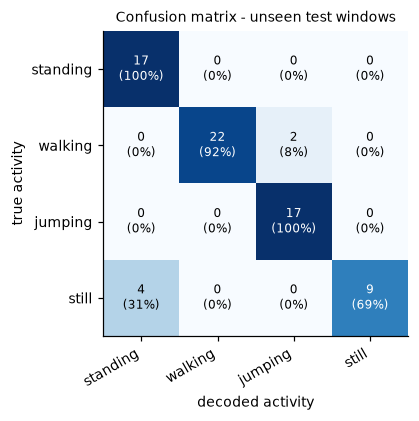

In [17]:
def heatmap(ax, M, labels, fmt, title, vmax=None, cmap="Blues", xlabel="", ylabel=""):
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else M.max())
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right"); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt(i, j), ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.55 * (vmax or M.max()) else "black")
    ax.set_title(title, fontsize=9); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(False)

fig, ax = plt.subplots(figsize=(4.6, 3.9))
rowpct = CM / CM.sum(1, keepdims=True)
heatmap(ax, rowpct, ACTIVITIES, lambda i, j: f"{CM[i, j]}\n({rowpct[i, j] * 100:.0f}%)", "Confusion matrix - unseen test windows", vmax=1,
        xlabel="decoded activity", ylabel="true activity")
fig.tight_layout(); fig.savefig(FIG / "fig04_confusion_matrix_test.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.4 Transition matrix

Initial transition matrix (supervised, before Baum-Welch):


,standing,walking,jumping,still
standing,0.870,0.042,0.054,0.035
walking,0.034,0.889,0.035,0.041
jumping,0.037,0.034,0.891,0.037
still,0.040,0.045,0.040,0.875


Transition matrix after Baum-Welch:


,standing,walking,jumping,still
standing,0.858,0.046,0.046,0.050
walking,0.034,0.879,0.047,0.041
jumping,0.038,0.038,0.887,0.038
still,0.059,0.048,0.040,0.853


initial distribution pi: {'standing': 0.25, 'walking': 0.25, 'jumping': 0.25, 'still': 0.25}
expected dwell time (windows, 1 window = 1 s hop): {'standing': 7.0, 'walking': 8.3, 'jumping': 8.8, 'still': 6.8}


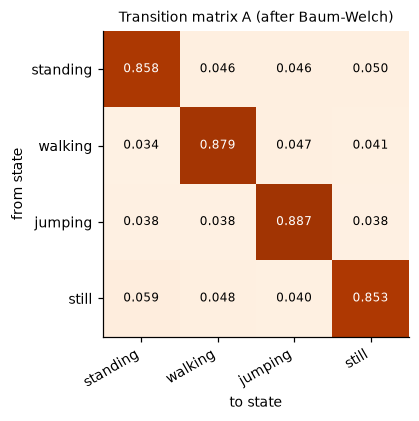

In [18]:
A_bw = params_bw["A"]
print("Initial transition matrix (supervised, before Baum-Welch):"); display(pd.DataFrame(params_init["A"], index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("Transition matrix after Baum-Welch:"); display(pd.DataFrame(A_bw, index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("initial distribution pi:", {a: round(float(p), 3) for a, p in zip(ACTIVITIES, params_bw["pi"])})
DWELL = 1 / (1 - np.diag(A_bw))
print("expected dwell time (windows, 1 window = 1 s hop):", {a: round(float(v), 1) for a, v in zip(ACTIVITIES, DWELL)})
fig, ax = plt.subplots(figsize=(4.6, 3.9))
heatmap(ax, A_bw, ACTIVITIES, lambda i, j: f"{A_bw[i, j]:.3f}", "Transition matrix A (after Baum-Welch)", vmax=1, cmap="Oranges",
        xlabel="to state", ylabel="from state")
fig.tight_layout(); fig.savefig(FIG / "fig05_transition_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.5 Emission probabilities

Most discriminative features (Fisher ratio, training data):


,Fisher ratio
acc_rms_z,54.71
acc_sma,51.41
acc_std_z,49.98
acc_energy_z,41.12
gyro_std_y,38.65
gyro_rms_y,36.11
gyro_sma,33.07
gyro_energy_y,30.41
acc_rms_y,28.38
acc_std_y,28.27


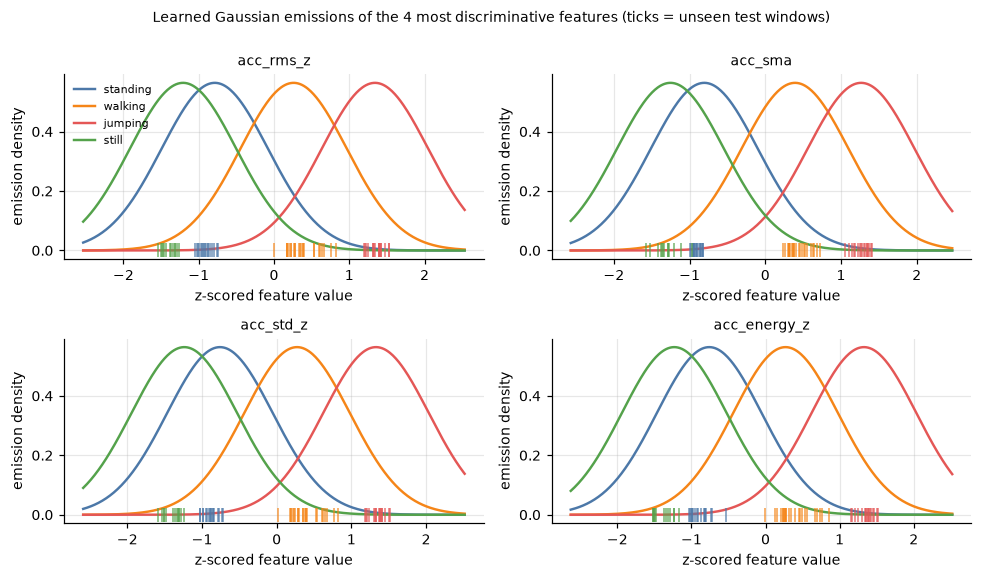

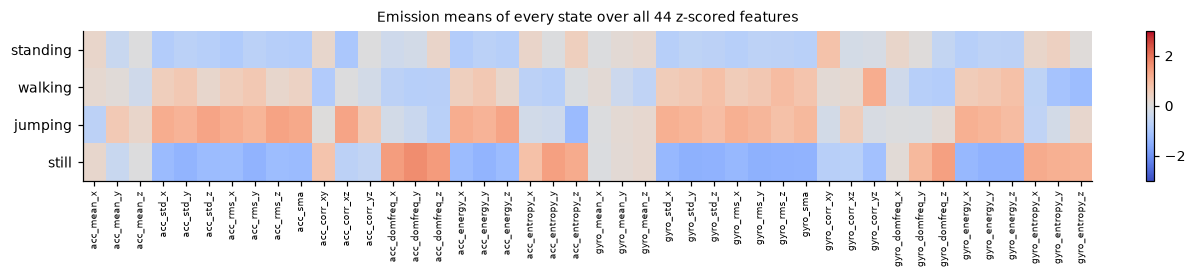

In [19]:
# Fisher score on TRAIN windows: between-class variance / within-class variance of each z-scored feature
ytr = np.concatenate([c["y"] for c in train_clips])
gm = Ztr.mean(0)
between = sum((ytr == k).sum() * (Ztr[ytr == k].mean(0) - gm) ** 2 for k in range(K))
within = sum((ytr == k).sum() * Ztr[ytr == k].var(0) for k in range(K))
fisher = pd.Series(between / (within + 1e-9), index=FEATURE_NAMES).sort_values(ascending=False)
print("Most discriminative features (Fisher ratio, training data):"); display(fisher.head(10).round(2).to_frame("Fisher ratio"))
top4 = list(fisher.index[:4])

fig, axes = plt.subplots(2, 2, figsize=(9, 5.2))
for ax, fn in zip(axes.ravel(), top4):
    d = FEATURE_NAMES.index(fn)
    lo, hi = min(Ztr[:, d].min(), Zte[:, d].min()) - 1, max(Ztr[:, d].max(), Zte[:, d].max()) + 1
    x = np.linspace(lo, hi, 400)
    for s in range(K):                       # state s is plotted under the activity it decodes to
        a = ACTIVITIES[MAP_BW[s]]; m, v = params_bw["mu"][s, d], params_bw["var"][s, d]
        ax.plot(x, np.exp(-(x - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), color=COLORS[a], label=a, lw=1.6)
    for c in test_clips:
        ax.plot(c["Z"][:, d], np.zeros(len(c["Z"])), "|", color=COLORS[c["activity"]], ms=9, alpha=.8, clip_on=False)
    ax.set_title(fn, fontsize=9); ax.set_xlabel("z-scored feature value"); ax.set_ylabel("emission density")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Learned Gaussian emissions of the 4 most discriminative features (ticks = unseen test windows)", fontsize=9, y=1.0)
fig.tight_layout(); fig.savefig(FIG / "fig06_emission_gaussians.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(11, 2.6))
mu_state = params_bw["mu"][np.argsort(MAP_BW)]            # rows ordered as ACTIVITIES
im = ax.imshow(mu_state, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3); ax.grid(False)
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xticks(range(D)); ax.set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=6)
ax.set_title(f"Emission means of every state over all {D} z-scored features", fontsize=9); fig.colorbar(im, ax=ax, fraction=.015)
fig.tight_layout(); fig.savefig(FIG / "fig08_state_means_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.6 Cadence and noise (descriptive)

Per-window dominant frequency (0.5 Hz FFT resolution) of each accelerometer axis, median over all train and test windows of each activity, and the median accelerometer-magnitude
std per clip. Descriptive only: not used for any choice.

In [20]:
dom_rows = []
for a in ACTIVITIES:
    Fa = np.concatenate([c["F_raw"] for c in clips if c["activity"] == a])
    row = {"activity": a, "windows": len(Fa)}
    for ax in "xyz":
        row[f"acc_{ax} median dominant freq (Hz)"] = float(np.median(Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")]))
    row["share of acc windows with a dominant bin in 1.0-2.5 Hz"] = float(np.mean([(Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")] >= 1.0) &
                                                                                   (Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")] <= 2.5) for ax in "xyz"]))
    row["median accel-magnitude std per clip"] = float(np.median([accel_std(c) for c in clips if c["activity"] == a]))
    dom_rows.append(row)
dom_tab = pd.DataFrame(dom_rows); display(dom_tab.round(3)); dom_tab.to_csv(RES / "dominant_frequency_by_activity.csv", index=False)

,activity,windows,acc_x median dominant freq (Hz),acc_y median dominant freq (Hz),acc_z median dominant freq (Hz),share of acc windows with a dominant bin in 1.0-2.5 Hz,median accel-magnitude std per clip
0,standing,75,2.002,2.503,4.505,0.347,0.089
1,walking,92,0.501,1.502,1.502,0.598,0.778
2,jumping,90,2.002,2.002,2.002,0.874,5.545
3,still,71,5.006,6.007,7.008,0.009,0.040


### 8.7 Decoded sequence over time, and where the errors are

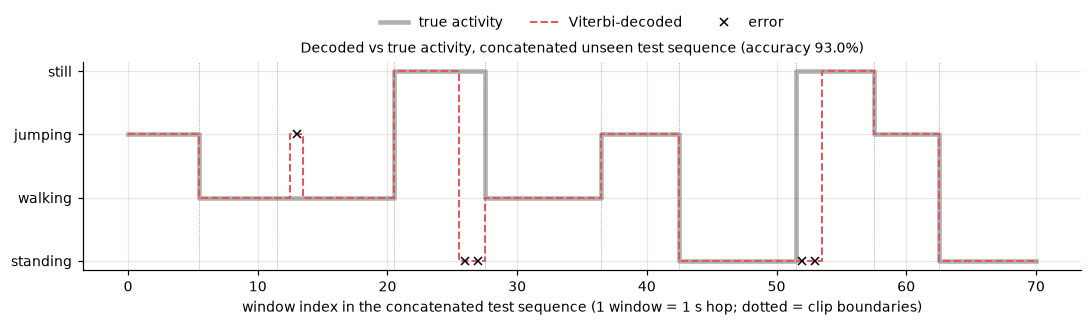

,clip,window,windows_in_clip,window_start_s,true,decoded
0,still_01.csv,5,7,5.0,still,standing
1,still_01.csv,6,7,6.0,still,standing
2,still_12.csv,0,6,0.0,still,standing
3,still_12.csv,1,6,1.0,still,standing
4,walking_13.csv,0,9,0.0,walking,jumping
5,walking_13.csv,1,9,1.0,walking,jumping


6 test errors; 4 of them in the first two windows (first 3 s) of a clip; windows per test clip: min 5, max 9


In [21]:
fig, ax = plt.subplots(figsize=(10, 3.2))
t = np.arange(len(y_cat))
ax.step(t, y_cat, where="mid", color="#222", lw=3, alpha=.35, label="true activity")
ax.step(t, p_cat, where="mid", color="#E45756", lw=1.3, ls="--", label="Viterbi-decoded")
wrong = np.where(y_cat != p_cat)[0]; ax.plot(wrong, p_cat[wrong], "x", color="k", ms=5, label="error")
edges = np.cumsum([len(test_clips[i]["y"]) for i in ORDER])
for e in edges[:-1]: ax.axvline(e - .5, color="gray", lw=.5, ls=":")
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel("window index in the concatenated test sequence (1 window = 1 s hop; dotted = clip boundaries)")
ax.set_title(f"Decoded vs true activity, concatenated unseen test sequence (accuracy {np.mean(y_cat == p_cat):.1%})", fontsize=9)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.28))
fig.tight_layout(); fig.savefig(FIG / "fig07_decoded_sequence.png", dpi=150, bbox_inches="tight"); plt.show()

# trace every per-clip test error: which window of which clip?
err_rows = []
for f, p in zip(test_clips, pred_bw):
    for w in np.where(p != f["y"])[0]:
        err_rows.append(dict(clip=f["name"], window=int(w), windows_in_clip=len(p), window_start_s=round(float(w * HOP / FS), 1),
                             true=f["activity"], decoded=ACTIVITIES[p[w]]))
err_tab = pd.DataFrame(err_rows, columns=["clip", "window", "windows_in_clip", "window_start_s", "true", "decoded"])
N_ERR = len(err_tab); N_ERR_FIRST2 = int((err_tab.window < 2).sum()) if N_ERR else 0
display(err_tab)
print(f"{N_ERR} test errors; {N_ERR_FIRST2} of them in the first two windows (first 3 s) of a clip; "
      f"windows per test clip: min {min(len(f['y']) for f in test_clips)}, max {max(len(f['y']) for f in test_clips)}")

### 8.8 Robustness check of the variance floor (reported for transparency, not used to choose anything)

The floor was fixed by the training-set rule in 7.3. The table shows how test accuracy and Baum-Welch behave for each candidate floor, with the same pi decision. Choosing a floor from this table would be tuning on the test set, so the floor stays at the value the training rule selected.

In [22]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

sens_rows = []
for fl in FLOORS:
    p0 = init_from_labels(seq_X, seq_y, fl, given_pi=PI0)
    p1, h1, cv1 = baum_welch(seq_X, p0, fl, eps=EPS, max_iter=MAX_ITER, update_pi=UPDATE_PI)
    mp1, _ = best_mapping(p1, train_clips)
    yt1, yp1 = pooled(test_clips, predict_files(p1, mp1, test_clips))
    _, yp0 = pooled(test_clips, predict_files(p0, best_mapping(p0, train_clips)[0], test_clips))
    sens_rows.append({"var_floor": fl, "BW iterations": len(h1) - 1, "BW converged": cv1, "LL gain from BW": h1[-1] - h1[0],
                      "variances at floor": float((p1["var"] <= fl + 1e-12).mean()),
                      "test accuracy (init only)": np.mean(yt1 == yp0), "test accuracy (after BW)": np.mean(yt1 == yp1)})
sens_tab = pd.DataFrame(sens_rows); display(sens_tab.round(4))
k_ok, n_all = int(np.trace(CM)), int(CM.sum()); lo, hi = wilson(k_ok, n_all)
print(f"primary model: {k_ok}/{n_all} windows correct = {k_ok / n_all:.3f}; 95% Wilson interval {lo:.3f}-{hi:.3f} "
      f"(optimistic: overlapping windows of only {len(test_clips)} clips are not independent)")

,var_floor,BW iterations,BW converged,LL gain from BW,variances at floor,test accuracy (init only),test accuracy (after BW)
0,0.01,3,True,3899.8807,0.1193,0.9859,0.9718
1,0.05,7,True,1356.4135,0.4886,1.0000,1.0000
2,0.10,5,True,728.8489,0.5455,0.9859,0.9577
3,0.25,5,True,53.5063,0.6648,0.9577,0.9437
4,0.50,4,True,32.1848,0.7955,0.9155,0.9155


primary model: 65/71 windows correct = 0.915; 95% Wilson interval 0.828-0.961 (optimistic: overlapping windows of only 10 clips are not independent)


## 9. Saved results and computed findings

`results/` receives every table the report quotes. The findings printed here are the facts the report is written from; interpretation lives in the report.

In [23]:
tab.to_csv(RES / "test_per_activity.csv", index=False)
pd.DataFrame(CM, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "test_confusion_matrix.csv")
pd.DataFrame(CM_cat, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "test_confusion_matrix_concatenated.csv")
pd.DataFrame(A_bw, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "transition_matrix.csv")
per_file.to_csv(RES / "test_per_clip.csv", index=False)
err_tab.to_csv(RES / "test_errors.csv", index=False)
cmp_tab.to_csv(RES / "model_comparison.csv", index=False)
cv.to_csv(RES / "variance_floor_cv.csv", index=False)
pi_cv.to_csv(RES / "pi_update_cv.csv", index=False)
fisher.head(10).to_csv(RES / "top_features_fisher.csv", header=["fisher_ratio"])
sens_tab.to_csv(RES / "variance_floor_sensitivity_posthoc.csv", index=False)
seconds = manifest.groupby("activity").duration_s.sum().reindex(ACTIVITIES)
metrics = dict(
    seed=SEED, window_samples=WIN, hop_samples=HOP, n_features=D, var_floor=VAR_FLOOR, update_pi=UPDATE_PI, eps=EPS, max_iter=MAX_ITER,
    n_train_sequences=N_SEQ, trim_s=float(manifest.trim_s.iloc[0]),
    measured_hz_mean=FS, measured_hz_min=float(hz_tab.hz.min()), measured_hz_max=float(hz_tab.hz.max()), measured_hz_std=float(hz_tab.hz.std()),
    n_train_clips=len(train_clips), n_test_clips=len(test_clips),
    n_train_windows=int(len(Ztr)), n_test_windows=int(len(Zte)),
    seconds_per_activity={a: float(round(v, 1)) for a, v in seconds.items()},
    bw_converged=bool(converged), bw_iterations=int(n_iter), ll_first=float(ll_hist[0]), ll_final=float(ll_hist[-1]),
    ll_min_step=float(np.diff(ll_hist).min()),
    overall_accuracy_per_clip=float(overall), overall_accuracy_concatenated=float(np.trace(CM_cat) / CM_cat.sum()),
    train_accuracy_resubstitution=TRAIN_ACC, train_accuracy_lofo=LOFO_FINAL,
    accuracy_init_only_per_clip=float(cmp_tab.iloc[1, 1]), accuracy_emission_only_per_clip=float(cmp_tab.iloc[2, 1]),
    variances_at_floor=PINNED, median_unfloored_variance=float(np.median(raw_var)),
    overall_accuracy_wilson95=[float(lo), float(hi)], correct_windows=k_ok, test_windows=n_all,
    n_test_errors=N_ERR, n_test_errors_in_first_two_windows=N_ERR_FIRST2,
    state_to_activity={ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_BW)},
    top_features=list(fisher.index[:4]),
)
(RES / "metrics.json").write_text(json.dumps(metrics, indent=2))

# facts for the report
met = tab.set_index("Activity")
best_s, worst_s = met.Sensitivity.max(), met.Sensitivity.min()
off = A_bw[~np.eye(K, dtype=bool)]
findings = dict(
    sensitivity_best=[a for a in ACTIVITIES if met.Sensitivity[a] == best_s],
    sensitivity_worst=[a for a in ACTIVITIES if met.Sensitivity[a] == worst_s],
    per_activity={a: dict(n=int(met["Number of Samples"][a]), sensitivity=float(met.Sensitivity[a]), specificity=float(met.Specificity[a]))
                  for a in ACTIVITIES},
    A_diagonal={a: float(A_bw[i, i]) for i, a in enumerate(ACTIVITIES)}, A_offdiag_min=float(off.min()), A_offdiag_max=float(off.max()),
    A_self_transitions_dominate=bool(all(A_bw[i, i] > A_bw[i].max() - 1e-12 for i in range(K)) and all(A_bw[i, i] > 0.5 for i in range(K))),
    dwell_windows={a: float(v) for a, v in zip(ACTIVITIES, DWELL)},
    median_accel_std={a: float(dom_tab.set_index("activity").loc[a, "median accel-magnitude std per clip"]) for a in ACTIVITIES},
    still_to_standing_std_ratio=float(dom_tab.set_index("activity").loc["standing", "median accel-magnitude std per clip"] /
                                      dom_tab.set_index("activity").loc["still", "median accel-magnitude std per clip"]),
    median_dominant_freq_hz={a: {ax: float(dom_tab.set_index("activity").loc[a, f"acc_{ax} median dominant freq (Hz)"]) for ax in "xyz"} for a in ACTIVITIES},
    walking_share_dom_1_to_2p5_hz=float(dom_tab.set_index("activity").loc["walking", "share of acc windows with a dominant bin in 1.0-2.5 Hz"]),
    nyquist_hz=FS / 2, hop_s=HOP / FS, window_s=WIN / FS,
    seconds_per_activity=metrics["seconds_per_activity"], activities_below_90s=[a for a in ACTIVITIES if seconds[a] < MIN_TOTAL_S],
    test_errors=err_tab.to_dict(orient="records"),
)
(RES / "findings.json").write_text(json.dumps(findings, indent=2))
print(json.dumps(metrics, indent=2))
print("\nFINDINGS")
print("usable seconds per activity:", metrics["seconds_per_activity"], "| below 90 s:", findings["activities_below_90s"] or "none")
print(f"test accuracy {overall:.3f} ({k_ok}/{n_all}); training windows (resubstitution) {TRAIN_ACC:.3f}; training leave-one-clip-out {LOFO_FINAL:.3f}")
print("highest sensitivity:", findings["sensitivity_best"], "| lowest sensitivity:", findings["sensitivity_worst"])
print("A diagonal:", {a: round(v, 3) for a, v in findings["A_diagonal"].items()}, f"| off-diagonal range {findings['A_offdiag_min']:.3f}-{findings['A_offdiag_max']:.3f}",
      "| self-transitions dominate:", findings["A_self_transitions_dominate"])
print("expected dwell (windows):", {a: round(v, 1) for a, v in findings["dwell_windows"].items()})
print(f"test errors: {N_ERR}, of which in the first two windows of a clip: {N_ERR_FIRST2}")
print("median accelerometer-magnitude std per clip:", {a: round(v, 3) for a, v in findings["median_accel_std"].items()},
      f"| standing/still ratio {findings['still_to_standing_std_ratio']:.2f}")
print(f"sampling rate {FS:.3f} Hz -> Nyquist {FS / 2:.1f} Hz; window {WIN / FS:.2f} s -> FFT resolution {FS / WIN:.2f} Hz")
print("accuracy per-clip: primary", f"{overall:.3f}", "| init only", f"{cmp_tab.iloc[1, 1]:.3f}", "| emission only", f"{cmp_tab.iloc[2, 1]:.3f}")

{
  "seed": 42,
  "window_samples": 200,
  "hop_samples": 100,
  "n_features": 44,
  "var_floor": 0.5,
  "update_pi": false,
  "eps": 0.0001,
  "max_iter": 500,
  "n_train_sequences": 10,
  "trim_s": 0.5,
  "measured_hz_mean": 100.1184477439876,
  "measured_hz_min": 100.10519053421335,
  "measured_hz_max": 100.12361155973586,
  "measured_hz_std": 0.005042361045630921,
  "n_train_clips": 40,
  "n_test_clips": 10,
  "n_train_windows": 257,
  "n_test_windows": 71,
  "seconds_per_activity": {
    "standing": 92.3,
    "walking": 108.6,
    "jumping": 107.8,
    "still": 88.2
  },
  "bw_converged": true,
  "bw_iterations": 4,
  "ll_first": -95853.15719687639,
  "ll_final": -95820.97236521586,
  "ll_min_step": 3.242109960410744e-05,
  "overall_accuracy_per_clip": 0.9154929577464789,
  "overall_accuracy_concatenated": 0.9295774647887324,
  "train_accuracy_resubstitution": 0.9883268482490273,
  "train_accuracy_lofo": 0.9844357976653697,
  "accuracy_init_only_per_clip": 0.9154929577464789,
  "a